In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_error
)

import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv('train.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
## Step 1: Explore the dataset

In [ ]:
## Check column names
print(df.columns.tolist())

['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC'

In [ ]:
# View the first five rows
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
# Check dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [ ]:
# Check the number of rows and columns
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 1460
Columns: 81


In [ ]:
# Check descriptive statistics
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:
# step 2: Check missing values and duplicates

In [ ]:
# Count missing values
missing_values = df.isnull().sum()

missing_values = missing_values[
    missing_values > 0
].sort_values(ascending=False)

print(missing_values.head(20))

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [ ]:
# Calculate missing-value percentagesCalculate missing-value percentages
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).sort_values(ascending=False)

print(missing_percentage[missing_percentage > 0].head(20))

PoolQC          99.520548
MiscFeature     96.301370
Alley           93.767123
Fence           80.753425
MasVnrType      59.726027
FireplaceQu     47.260274
LotFrontage     17.739726
GarageQual       5.547945
GarageFinish     5.547945
GarageType       5.547945
GarageYrBlt      5.547945
GarageCond       5.547945
BsmtFinType2     2.602740
BsmtExposure     2.602740
BsmtCond         2.534247
BsmtQual         2.534247
BsmtFinType1     2.534247
MasVnrArea       0.547945
Electrical       0.068493
dtype: float64


In [ ]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
df = df.drop_duplicates().copy()

print("Shape after duplicate removal:", df.shape)

Shape after duplicate removal: (1460, 81)


In [ ]:
# Step 3: Analyze the target variable — SalePrice

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


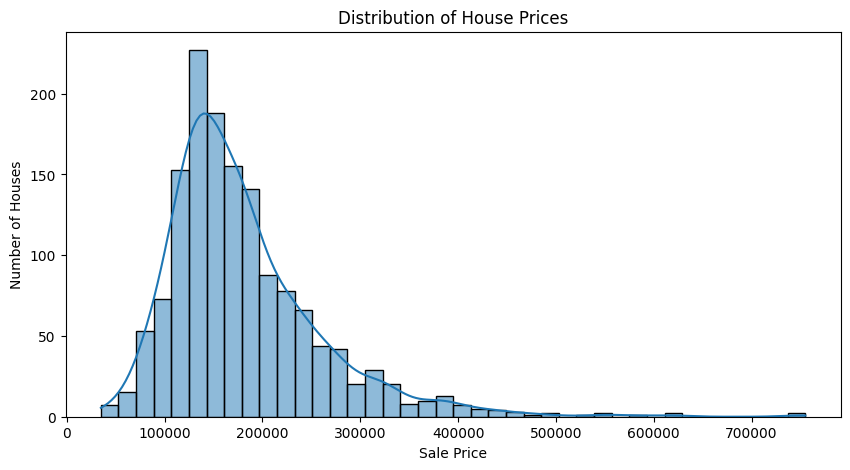

In [ ]:
print(df['SalePrice'].describe())
# Plot the distribution of house prices
plt.figure(figsize=(10, 5))

sns.histplot(
    df['SalePrice'],
    bins=40,
    kde=True
)

plt.title('Distribution of House Prices')
plt.xlabel('Sale Price')
plt.ylabel('Number of Houses')

plt.show()

In [ ]:
# Check for missing target values
print("Missing SalePrice values:", df['SalePrice'].isnull().sum())

Missing SalePrice values: 0


In [ ]:
# Step 4: Select relevant features

In [ ]:
'''
### Feature Selection Discussion

The selected features represent important characteristics that may influence house prices. Overall quality and living area describe the condition and size of a property, while basement area, garage capacity, bathrooms, and bedrooms provide information about its facilities. Year built represents the age of the property, and lot area describes the size of the land. Neighborhood and house style are categorical features that may capture location-related and design-related price differences.

These features will be used to train a Linear Regression model to predict `SalePrice`. Their actual importance will be examined using correlation analysis and the fitted model's coefficients.
'''

"\n### Feature Selection Discussion\n\nThe selected features represent important characteristics that may influence house prices. Overall quality and living area describe the condition and size of a property, while basement area, garage capacity, bathrooms, and bedrooms provide information about its facilities. Year built represents the age of the property, and lot area describes the size of the land. Neighborhood and house style are categorical features that may capture location-related and design-related price differences.\n\nThese features will be used to train a Linear Regression model to predict `SalePrice`. Their actual importance will be examined using correlation analysis and the fitted model's coefficients.\n"

In [ ]:
features = [
    'OverallQual',
    'GrLivArea',
    'TotalBsmtSF',
    'GarageCars',
    'YearBuilt',
    'FullBath',
    'BedroomAbvGr',
    'LotArea',
    'Neighborhood',
    'HouseStyle'
]

target = 'SalePrice'

X = df[features].copy()
y = df[target].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

X.head()

Feature shape: (1460, 10)
Target shape: (1460,)


,OverallQual,GrLivArea,TotalBsmtSF,GarageCars,YearBuilt,FullBath,BedroomAbvGr,LotArea,Neighborhood,HouseStyle
0,7,1710,856,2,2003,2,3,8450,CollgCr,2Story
1,6,1262,1262,2,1976,2,3,9600,Veenker,1Story
2,7,1786,920,2,2001,2,3,11250,CollgCr,2Story
3,7,1717,756,3,1915,1,3,9550,Crawfor,2Story
4,8,2198,1145,3,2000,2,4,14260,NoRidge,2Story


In [ ]:
# Step 5: Perform correlation analysis

In [ ]:
# Correlation with house price
numeric_df = df[features].select_dtypes(
    include='number'
).copy()

numeric_df['SalePrice'] = y

price_correlation = numeric_df.corr()['SalePrice'].sort_values(
    ascending=False
)

print(price_correlation)

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
TotalBsmtSF     0.613581
FullBath        0.560664
YearBuilt       0.522897
LotArea         0.263843
BedroomAbvGr    0.168213
Name: SalePrice, dtype: float64


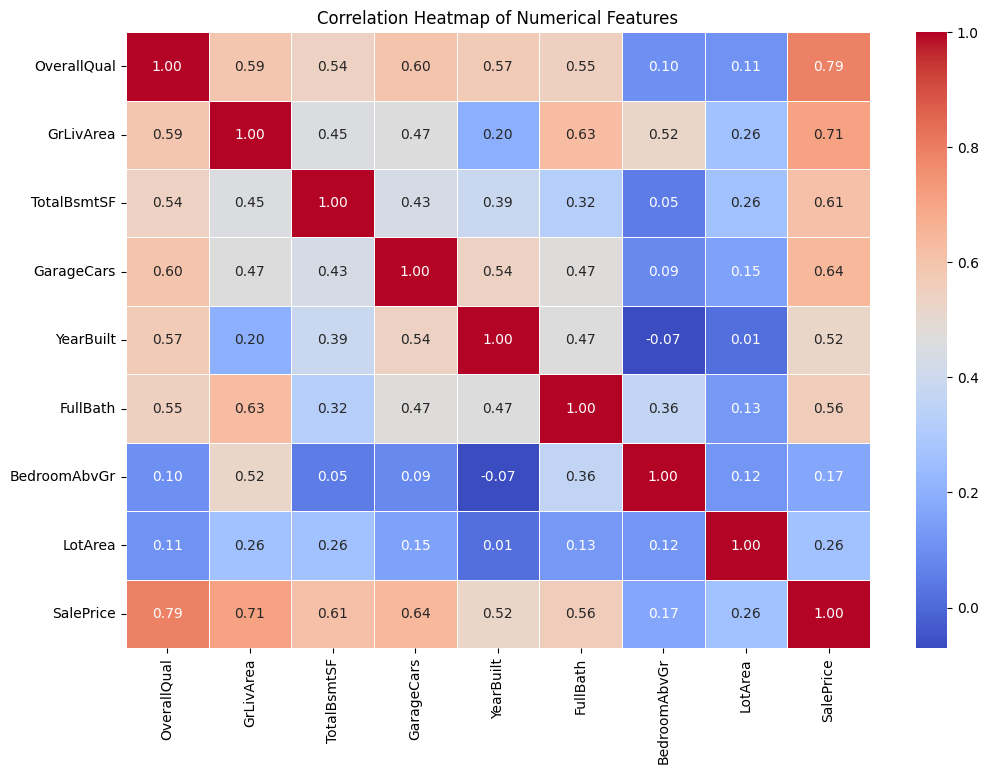

In [ ]:
# Draw a correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

In [ ]:
# Step 6: Prepare the training and testing data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 1168
Testing rows: 292


In [ ]:
# Step 7: Identify numerical and categorical features

In [ ]:
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'GarageCars', 'YearBuilt', 'FullBath', 'BedroomAbvGr', 'LotArea']
Categorical features: ['Neighborhood', 'HouseStyle']


In [ ]:
# Step 8: Handle missing values and encode categorical features

In [ ]:
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median'))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [ ]:
# Combine both preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [ ]:
# Check the preprocessing object
print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [ ]:
# Step 9: Train the Linesr Regression model

In [ ]:
linear_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [ ]:
# Step 10: Predict house prices

In [ ]:
y_pred = linear_model.predict(X_test)

print("First 10 actual prices:")
print(y_test.head(10).values)

print("\nFirst 10 predicted prices:")
print(np.round(y_pred[:10], 2))

First 10 actual prices:
[154500 325000 115000 159000 315500  75500 311500 146000  84500 135500]

First 10 predicted prices:
[138645.83 325935.69 119310.75 178443.74 277080.91  77480.16 233976.17
 158245.61  77009.49 118443.24]


In [ ]:
# Compare actual and predicted prices in a table:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': np.round(y_pred, 2)
})

comparison.head(10)

,Actual Price,Predicted Price
0,154500,138645.83
1,325000,325935.69
2,115000,119310.75
3,159000,178443.74
4,315500,277080.91
5,75500,77480.16
6,311500,233976.17
7,146000,158245.61
8,84500,77009.49
9,135500,118443.24


In [ ]:
# Step 11: Evaluate model performance

In [ ]:
# Mean Squared Error
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error (MSE):", round(mse, 2))

Mean Squared Error (MSE): 1302917180.21


In [ ]:
# Root mean squared error
rmse = np.sqrt(mse)

print("Root Mean Squared Error (RMSE):", round(rmse, 2))

Root Mean Squared Error (RMSE): 36095.94


In [ ]:
# r2 score
r2 = r2_score(y_test, y_pred)

print("R² Score:", round(r2, 4))

R² Score: 0.8301


In [ ]:
# Display all matrix together
print("MODEL EVALUATION")
print("------------------------------")
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))

MODEL EVALUATION
------------------------------
MSE : 1302917180.21
RMSE: 36095.94
R²  : 0.8301


In [ ]:
# Step 12: Plot actual prices vs. predicted prices

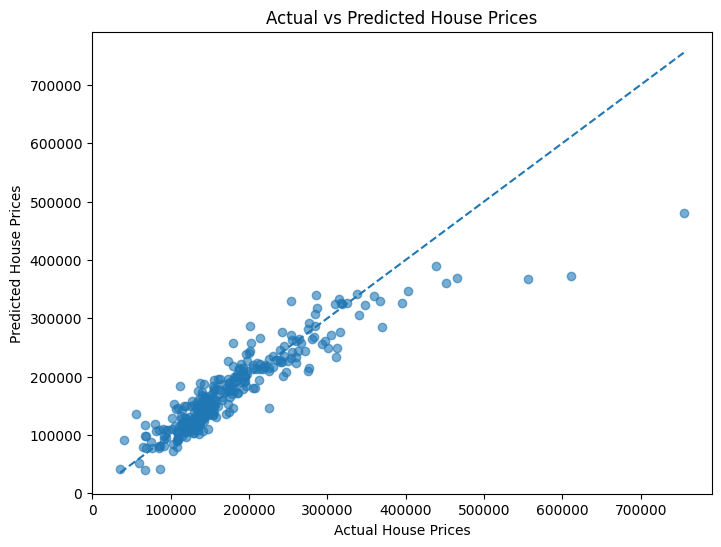

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle='--'
)

plt.xlabel('Actual House Prices')
plt.ylabel('Predicted House Prices')
plt.title('Actual vs Predicted House Prices')

plt.show()

In [ ]:
# Step 13: Plot the residuals

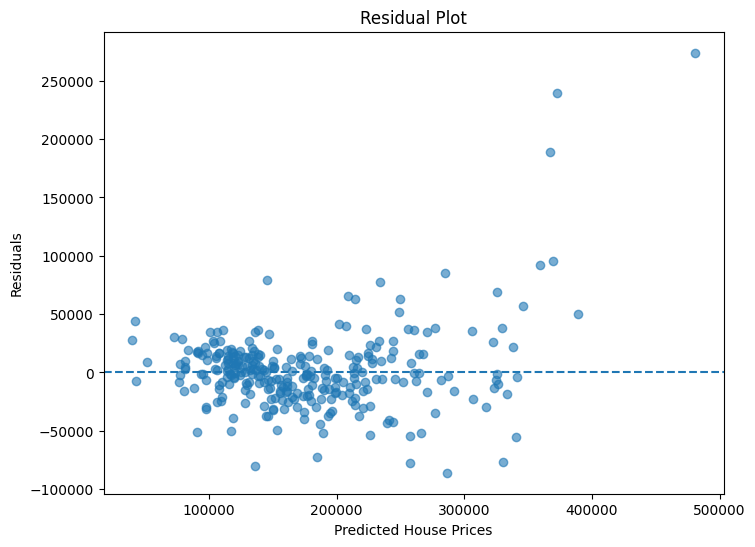

In [ ]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel('Predicted House Prices')
plt.ylabel('Residuals')
plt.title('Residual Plot')

plt.show()

In [ ]:
# Step 14: Analyze model coefficients

In [ ]:
# Get the trained preprocessing object
fitted_preprocessor = linear_model.named_steps['preprocessor']

# Get feature names after One-Hot Encoding
feature_names = fitted_preprocessor.get_feature_names_out()

# Get Linear Regression coefficients
coefficients = linear_model.named_steps['model'].coef_

coefficient_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

coefficient_df['Impact'] = np.where(
    coefficient_df['Coefficient'] > 0,
    'Positive',
    'Negative'
)

coefficient_df['Absolute Coefficient'] = (
    coefficient_df['Coefficient'].abs()
)

coefficient_df = coefficient_df.sort_values(
    'Absolute Coefficient',
    ascending=False
)

print(coefficient_df.head(15))

                      Feature   Coefficient    Impact  Absolute Coefficient
24  cat__Neighborhood_NridgHt  42995.885457  Positive          42995.885457
23  cat__Neighborhood_NoRidge  41316.010803  Positive          41316.010803
30  cat__Neighborhood_StoneBr  33986.544340  Positive          33986.544340
14  cat__Neighborhood_Crawfor  25059.144537  Positive          25059.144537
8   cat__Neighborhood_Blmngtn -24989.658705  Negative          24989.658705
10   cat__Neighborhood_BrDale -18207.204312  Negative          18207.204312
15  cat__Neighborhood_Edwards -18159.619994  Negative          18159.619994
22   cat__Neighborhood_NWAmes -17367.958074  Negative          17367.958074
28  cat__Neighborhood_SawyerW -17367.739898  Negative          17367.739898
19  cat__Neighborhood_Mitchel -17283.019561  Negative          17283.019561
0            num__OverallQual  16736.376556  Positive          16736.376556
32  cat__Neighborhood_Veenker  13340.174100  Positive          13340.174100
37     cat__

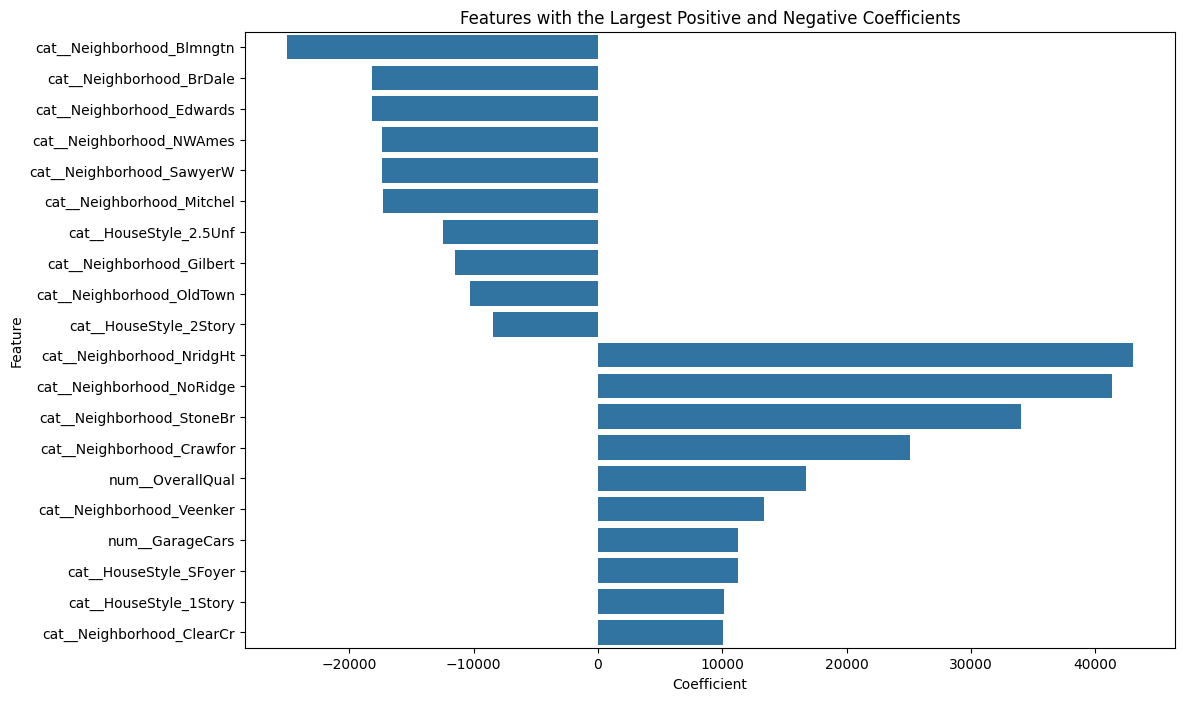

In [ ]:
# Plot the largest positive and negative coefficients
top_positive = coefficient_df.sort_values(
    'Coefficient',
    ascending=False
).head(10)

top_negative = coefficient_df.sort_values(
    'Coefficient',
    ascending=True
).head(10)

top_coefficients = pd.concat([
    top_negative,
    top_positive
]).drop_duplicates(subset='Feature')

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_coefficients,
    x='Coefficient',
    y='Feature'
)

plt.title('Features with the Largest Positive and Negative Coefficients')
plt.xlabel('Coefficient')
plt.ylabel('Feature')

plt.show()

In [ ]:
# Step 15: Bonus — Compare Linear Regression with Ridge Regression

In [ ]:
ridge_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', Ridge(alpha=10.0))
    ]
)

ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)

ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_pred)

print("RIDGE REGRESSION")
print("------------------------------")
print("MSE :", round(ridge_mse, 2))
print("RMSE:", round(ridge_rmse, 2))
print("R²  :", round(ridge_r2, 4))

RIDGE REGRESSION
------------------------------
MSE : 2010051695.88
RMSE: 44833.6
R²  : 0.7379


In [ ]:
# Compare both models
model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression'],
    'MSE': [mse, ridge_mse],
    'RMSE': [rmse, ridge_rmse],
    'R2 Score': [r2, ridge_r2]
})

print(model_comparison)

               Model           MSE          RMSE  R2 Score
0  Linear Regression  1.302917e+09  36095.944096  0.830135
1   Ridge Regression  2.010052e+09  44833.600077  0.737944


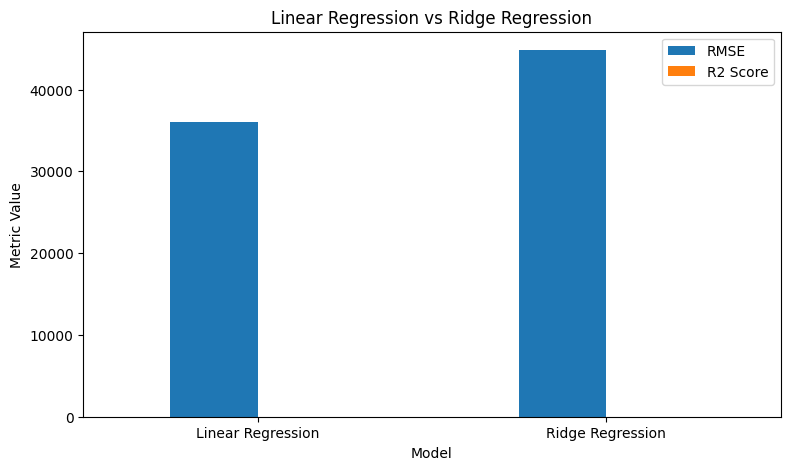

In [ ]:
# Plot the comparison:
model_comparison.set_index('Model')[
    ['RMSE', 'R2 Score']
].plot(kind='bar', figsize=(9, 5))

plt.title('Linear Regression vs Ridge Regression')
plt.ylabel('Metric Value')
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Step 16: Predict the price of a new house

In [ ]:
new_house = pd.DataFrame([{
    'OverallQual': 7,
    'GrLivArea': 1800,
    'TotalBsmtSF': 900,
    'GarageCars': 2,
    'YearBuilt': 2005,
    'FullBath': 2,
    'BedroomAbvGr': 3,
    'LotArea': 8000,
    'Neighborhood': 'NAmes',
    'HouseStyle': '2Story'
}])

predicted_price = linear_model.predict(new_house)[0]

print("Predicted House Price:", round(predicted_price, 2))

Predicted House Price: 210266.95


In [ ]:
# Step 17: Save the result

In [ ]:
final_predictions = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred,
    'Residual': residuals.values
})

final_predictions.to_csv(
    '/content/house_price_predictions.csv',
    index=False
)

print("Predictions saved successfully!")


Predictions saved successfully!
